<a href="https://colab.research.google.com/github/bhuvaneshwaranyai2024-alt/Gokuchi_detection/blob/main/Email_Spam_Detection_WebApp_1000_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Email Spam Detection — Web App + ML Backend (Google Colab)

**Stack:** TF-IDF word + character features, Linear SVM, evaluation metrics, Gradio web interface.

This notebook is designed to run in Google Colab. It attempts to download a real, public SpamAssassin email corpus and build a reproducible 1,000-email dataset (500 spam + 500 legitimate examples) from it. If the download is unavailable, it falls back to the uploaded CSV dataset.

**Dataset note:** The separate `email_spam_dataset_1000.csv` file included with this notebook is synthetic demonstration data. For the more realistic model, use the notebook's public-corpus download cell. No accuracy value is guaranteed; report the metrics actually produced by your run.

## 1. Install requirements

In [ ]:
%pip -q install gradio scikit-learn pandas matplotlib

## 2. Build a 1,000-email dataset from the public SpamAssassin corpus
This cell downloads public SpamAssassin archives, parses email subject/body, removes duplicates, and saves `email_spam_dataset_real_1000.csv`. If the download fails, upload the provided CSV file in the next cell instead.

In [ ]:
import os, re, tarfile, urllib.request, tempfile, random, email
from email import policy
from email.parser import BytesParser
import pandas as pd

random.seed(42)
CORPUS_URLS = {
    "spam": [
        "https://spamassassin.apache.org/old/publiccorpus/20030228_spam_2.tar.bz2",
        "https://spamassassin.apache.org/old/publiccorpus/20021010_spam.tar.bz2",
    ],
    "ham": [
        "https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham_2.tar.bz2",
        "https://spamassassin.apache.org/old/publiccorpus/20030228_hard_ham.tar.bz2",
        "https://spamassassin.apache.org/old/publiccorpus/20021010_easy_ham.tar.bz2",
    ],
}

def clean_email_message(raw_bytes):
    try:
        msg = BytesParser(policy=policy.default).parsebytes(raw_bytes)
        subject = str(msg.get("subject", "") or "")
        parts = []
        if msg.is_multipart():
            for part in msg.walk():
                if part.get_content_type() == "text/plain" and not part.get_content_disposition():
                    try:
                        parts.append(str(part.get_content()))
                    except Exception:
                        pass
        elif msg.get_content_type() == "text/plain":
            try:
                parts.append(str(msg.get_content()))
            except Exception:
                pass
        body = "\n".join(parts)
        if not body:
            body = msg.get_body(preferencelist=("plain",))
            if body:
                try: body = str(body.get_content())
                except Exception: body = ""
        text = (f"Subject: {subject}\n\n{body}").strip()
        text = re.sub(r"\s+", " ", text)
        return text[:12000].strip()
    except Exception:
        return ""

def download_and_parse(url, label):
    parsed=[]
    with tempfile.NamedTemporaryFile(suffix=".tar.bz2") as tmp:
        urllib.request.urlretrieve(url, tmp.name)
        with tarfile.open(tmp.name, "r:bz2") as tar:
            for member in tar.getmembers():
                if not member.isfile() or member.size > 2_000_000:
                    continue
                try:
                    f=tar.extractfile(member)
                    if f:
                        text=clean_email_message(f.read())
                        if len(text) >= 30:
                            parsed.append({"text":text, "label":label, "source":"SpamAssassin public corpus"})
                except Exception:
                    continue
    return parsed

real_rows=[]
download_errors=[]
for label, urls in CORPUS_URLS.items():
    for url in urls:
        try:
            batch=download_and_parse(url,label)
            print(f"{label}: collected {len(batch)} from {url.split('/')[-1]}")
            real_rows.extend(batch)
        except Exception as e:
            download_errors.append(f"{url}: {e}")
            print("Could not download", url.split("/")[-1], "-", str(e)[:160])

if real_rows:
    real_df=pd.DataFrame(real_rows)
    real_df["text_norm"]=real_df["text"].str.lower().str.replace(r"\W+"," ",regex=True).str.strip()
    real_df=real_df.drop_duplicates("text_norm").drop(columns="text_norm")
    spam_df=real_df[real_df.label=="spam"]
    ham_df=real_df[real_df.label=="ham"]
    n_each=min(500,len(spam_df),len(ham_df))
    if n_each >= 100:
        balanced=pd.concat([
            spam_df.sample(n=n_each,random_state=42),
            ham_df.sample(n=n_each,random_state=42)
        ]).sample(frac=1,random_state=42).reset_index(drop=True)
        balanced=balanced[["text","label","source"]]
        balanced.to_csv("email_spam_dataset_real_1000.csv",index=False)
        print("Created real-corpus dataset:", balanced.shape, balanced.label.value_counts().to_dict())
        df=balanced[["text","label"]].copy()
    else:
        print("Not enough examples from both classes were downloaded. Use the fallback CSV in the next cell.")
        df=None
else:
    print("Public corpus download did not work in this runtime. Use the fallback CSV in the next cell.")
    df=None

spam: collected 1348 from 20030228_spam_2.tar.bz2
spam: collected 488 from 20021010_spam.tar.bz2
ham: collected 1400 from 20030228_easy_ham_2.tar.bz2
ham: collected 250 from 20030228_hard_ham.tar.bz2
ham: collected 2551 from 20021010_easy_ham.tar.bz2
Created real-corpus dataset: (1000, 3) {'ham': 500, 'spam': 500}


## 3. Load fallback dataset if needed
If the public dataset cell could not create `df`, upload `email_spam_dataset_1000.csv` from the downloaded files. Remember: that separate file is synthetic demo data.

In [ ]:
from google.colab import files
if "df" not in globals() or df is None:
    uploaded = files.upload()
    filename = next(iter(uploaded))
    if filename.lower().endswith(".csv"):
        df = pd.read_csv(filename)
    elif filename.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(filename)
    else:
        raise ValueError("Upload a CSV or Excel dataset.")
else:
    print("Using dataset already loaded from the public corpus.")

required={"text","label"}
if not required.issubset(df.columns):
    raise ValueError("Dataset must contain columns named 'text' and 'label'.")
df=df[["text","label"]].copy()
df["text"]=df["text"].fillna("").astype(str).str.strip()
df["label"]=df["label"].astype(str).str.lower().str.strip()
df=df[(df.text!="") & (df.label.isin(["spam","ham"]))]
df=df.drop_duplicates(subset=["text","label"]).reset_index(drop=True)
if df.label.nunique()!=2 or df.label.value_counts().min()<10:
    raise ValueError("Need at least 10 examples of each label (spam and ham).")
print("Rows:",len(df))
display(df.label.value_counts().rename_axis("label").to_frame("count"))
display(df.head(3))

Using dataset already loaded from the public corpus.
Rows: 1000


,count
label,
ham,500
spam,500


,text,label
0,Subject: Re: [zzzzteana] The Cafe Forteana is ...,ham
1,"Subject: Re: Google? Not in China >>>>> ""J"" ==...",ham
2,Subject: JOTD: Sean Connery three times a nigh...,ham


## 4. Train the model
Word and character TF-IDF help capture both meaningful phrases and unusual character patterns. LinearSVC is a strong baseline for sparse text classification. The test set is held out from training.

Test accuracy: 0.9950 (99.50%)
Spam precision: 0.9901
Spam recall:    1.0000
Spam F1-score:  0.9950

Classification report:
              precision    recall  f1-score   support

         ham       1.00      0.99      0.99       100
        spam       0.99      1.00      1.00       100

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200

Confusion matrix (rows=actual [ham, spam], columns=predicted [ham, spam]):
[[ 99   1]
 [  0 100]]
False positives (legitimate emails flagged as spam): 1


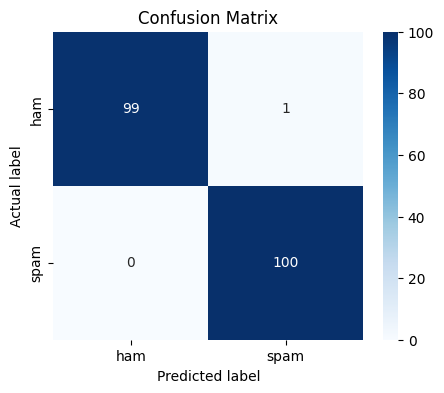

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.20, random_state=42, stratify=df["label"]
)

features = FeatureUnion([
    ("word", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=120000,
                             sublinear_tf=True, strip_accents="unicode")),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), min_df=2,
                             max_features=100000, sublinear_tf=True))
])

model = Pipeline([
    ("features", features),
    ("classifier", LinearSVC(class_weight="balanced", random_state=42))
])
model.fit(X_train, y_train)
y_pred=model.predict(X_test)

accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred,pos_label="spam",zero_division=0)
recall=recall_score(y_test,y_pred,pos_label="spam",zero_division=0)
f1=f1_score(y_test,y_pred,pos_label="spam",zero_division=0)

print(f"Test accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Spam precision: {precision:.4f}")
print(f"Spam recall:    {recall:.4f}")
print(f"Spam F1-score:  {f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test,y_pred,labels=["ham","spam"],zero_division=0))
cm=confusion_matrix(y_test,y_pred,labels=["ham","spam"])
print("Confusion matrix (rows=actual [ham, spam], columns=predicted [ham, spam]):")
print(cm)
false_positive_count=int(cm[0,1])
print("False positives (legitimate emails flagged as spam):",false_positive_count)

plt.figure(figsize=(5,4))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["ham","spam"],yticklabels=["ham","spam"])
plt.xlabel("Predicted label"); plt.ylabel("Actual label"); plt.title("Confusion Matrix")
plt.show()

## 5. Build and launch the webpage
Gradio provides the frontend; the trained scikit-learn pipeline is the backend. Run this cell, then open the public Gradio URL that Colab prints. Avoid entering private or confidential emails into a public demo link.

In [ ]:
import gradio as gr
from datetime import datetime

def classify_email(message):
    if not message or not message.strip():
        return "Please enter email text.", "No prediction", "Enter a message to begin."
    pred=model.predict([message.strip()])[0]
    # LinearSVC decision score is not a calibrated probability, so do not label it as one.
    score=float(model.decision_function([message.strip()])[0])
    if pred=="spam":
        result="🚨 SPAM / SUSPICIOUS"
        explanation="The model places this message on the spam side of its learned decision boundary. Verify the sender independently; do not click suspicious links."
    else:
        result="✅ LIKELY LEGITIMATE (HAM)"
        explanation="The model places this message on the legitimate side of its learned decision boundary. This is not a safety guarantee; still verify unexpected requests and links."
    score_text=f"Model decision score: {score:.3f} (not a probability)"
    return result, score_text, explanation

with gr.Blocks(theme=gr.themes.Soft(), title="Email Shield — Spam Detection") as demo:
    gr.Markdown("# 🛡️ Email Shield")
    gr.Markdown("### Machine-learning email spam detector")
    gr.Markdown("Paste the subject and body of an email. The model returns a prediction and a short explanation.")
    with gr.Row():
        with gr.Column(scale=2):
            email_input=gr.Textbox(label="Email subject and body", lines=10,
                placeholder="Subject: ...\n\nPaste email content here...")
            check_btn=gr.Button("Analyze Email", variant="primary")
            clear_btn=gr.ClearButton([email_input])
        with gr.Column(scale=1):
            result_out=gr.Textbox(label="Prediction", interactive=False)
            score_out=gr.Textbox(label="Model score", interactive=False)
            explanation_out=gr.Textbox(label="Interpretation", lines=5, interactive=False)
    check_btn.click(classify_email, inputs=email_input, outputs=[result_out,score_out,explanation_out])
    gr.Examples(
        examples=[
            ["Subject: Meeting notes\n\nPlease review the report before our team meeting tomorrow."],
            ["Subject: Claim your reward now\n\nYou have won a free gift card. Visit offers.example to claim immediately."]
        ],
        inputs=email_input
    )
    gr.Markdown("---\n**Limitations:** Predictions can be wrong. This prototype does not inspect sender authentication, attachments, or URLs. Do not treat it as a substitute for your email provider's security checks.")

demo.launch(share=True, debug=False)

/tmp/ipykernel_799/3255699313.py:19: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Email Shield — Spam Detection") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e70bf525b2fc4fbde1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 6. Save the trained model and evaluation report (optional)
The model file can be downloaded, but only load pickle/joblib model files that you created or trust.

In [ ]:
import joblib, json
joblib.dump(model, "email_spam_model.joblib")
metrics={
    "accuracy":float(accuracy),
    "spam_precision":float(precision),
    "spam_recall":float(recall),
    "spam_f1":float(f1),
    "test_examples":int(len(y_test)),
    "false_positives":int(false_positive_count)
}
with open("evaluation_metrics.json","w") as f:
    json.dump(metrics,f,indent=2)
print(metrics)
from google.colab import files
files.download("email_spam_model.joblib")
files.download("evaluation_metrics.json")

{'accuracy': 0.995, 'spam_precision': 0.9900990099009901, 'spam_recall': 1.0, 'spam_f1': 0.9950248756218906, 'test_examples': 200, 'false_positives': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project notes
- Preferred dataset source: SpamAssassin Public Corpus (publicly redistributable); the notebook records the source in the generated CSV.
- The included standalone 1,000-row CSV/XLSX is synthetic demonstration data, not a real email corpus.
- Use the real-corpus download path where available, and report only measured held-out test results.
- LinearSVC decision scores are not calibrated probabilities. The webpage intentionally avoids displaying them as confidence percentages.
- Test with new emails and review false positives before drawing conclusions.
- Do not send confidential messages to a public Gradio share URL.